In [ ]:
!unzip -q dataset_cleaned.zip
!ls dataset
!head -3 dataset/labels.csv

benign	labels.csv  malignant  normal  report.txt
path,cls,label3,group,orig_w,orig_h,crop_w,crop_h,fold,split
dataset/normal/normal_1.jpg,normal,0,normal_1,768,576,592,393,3,train
dataset/normal/normal_10.jpg,normal,0,normal_10,720,576,586,461,2,test


In [ ]:
!pip install -q xgboost lightgbm

In [ ]:
!python extract_features.py --data dataset --out features --aug 4

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth
100% 528M/528M [00:03<00:00, 156MB/s]
vgg16 (3675, 512)
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth
100% 97.8M/97.8M [00:00<00:00, 161MB/s]
resnet50 (3675, 2048)
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth
100% 30.8M/30.8M [00:00<00:00, 101MB/s]
densenet121 (3675, 1024)
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth
100% 20.5M/20.5M [00:00<00:00, 130MB/s]
efficientnet_b0 (3675, 1280)
Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth
100% 330M/330M [00:01<00:00, 174MB/s]
vit_b16 (36

In [ ]:
!python train_boosting.py --task three --eval cv --quick

task=three eval=cv images=735 classes={'normal': 100, 'benign': 200, 'malignant': 435}
Traceback (most recent call last):
  File "/content/train_boosting.py", line 96, in <module>
    P, _, bp = run_split(tr, te, mn, clf, grid, 3); oof[src[te]] = P; done[src[te]] = True
               ~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/content/train_boosting.py", line 89, in run_split
    est, cvs, bp = fit_predict(clf, grid, X[train_mask], y[train_mask], src[train_mask], X[test_mask], a.pca, inner)
                   ~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/content/train_boosting.py", line 56, in fit_predict
    gs.fit(Xtr, ytr, clf__sample_weight=compute_sample_weight('balanced', ytr))                      # class-imbalance handling
    ~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estima

In [ ]:
!grep -c "xgb-gpu" train_boosting.py


0


In [ ]:
!grep -c "xgb-gpu" train_boosting.py

1


In [ ]:
!python train_boosting.py --task three --eval holdout --quick --pca 0.95 --max-aug 2 --boosters XGBoost LightGBM --xgb-gpu

task=three eval=holdout images=735 classes={'normal': 100, 'benign': 200, 'malignant': 435}
>>> densenet121 + XGBoost ...
/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [06:45:15] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)
{'backbone': 'densenet121', 'booster': 'XGBoost', 'cv_AUC': np.float64(0.843), 'val_AUC': np.float64(0.858), 'test_accuracy': 0.771, 'test_precision': 0.743, 'test_recall': 0.742, 'test_F1': 0.741, 'test_AUC': np.float64(0.901), 'best_params': '{"learning_rate": 0.1, "max_depth": 3, "n_estimators": 100}', '_rank': np.floa

['results/cm_three_holdout_resnet50_LightGBM.png', 'results/cm_three_holdout_densenet121_LightGBM.png', 'results/roc_three_holdout.png', 'results/results_three_holdout.csv', 'results/cm_three_holdout_densenet121_XGBoost.png']


,backbone,booster,cv_AUC,val_AUC,test_accuracy,test_precision,test_recall,test_F1,test_AUC,best_params
0,densenet121,LightGBM,0.852,0.864,0.762,0.749,0.712,0.727,0.908,"{""learning_rate"": 0.1, ""n_estimators"": 100, ""n..."
1,densenet121,XGBoost,0.843,0.858,0.771,0.743,0.742,0.741,0.901,"{""learning_rate"": 0.1, ""max_depth"": 3, ""n_esti..."
2,resnet50,LightGBM,0.831,0.857,0.743,0.696,0.720,0.699,0.890,"{""learning_rate"": 0.1, ""n_estimators"": 100, ""n..."
3,vgg16,LightGBM,0.827,0.847,0.771,0.716,0.724,0.713,0.880,"{""learning_rate"": 0.1, ""n_estimators"": 100, ""n..."
4,efficientnet_b0,LightGBM,0.839,0.838,0.695,0.611,0.601,0.598,0.878,"{""learning_rate"": 0.1, ""n_estimators"": 100, ""n..."
5,efficientnet_b0,XGBoost,0.828,0.827,0.695,0.602,0.620,0.600,0.874,"{""learning_rate"": 0.1, ""max_depth"": 3, ""n_esti..."
6,resnet50,XGBoost,0.815,0.848,0.743,0.682,0.726,0.691,0.870,"{""learning_rate"": 0.1, ""max_depth"": 3, ""n_esti..."
7,vit_b16,LightGBM,0.840,0.855,0.733,0.713,0.622,0.652,0.858,"{""learning_rate"": 0.1, ""n_estimators"": 100, ""n..."
8,vgg16,XGBoost,0.811,0.814,0.676,0.598,0.640,0.607,0.845,"{""learning_rate"": 0.1, ""max_depth"": 3, ""n_esti..."
9,vit_b16,XGBoost,0.813,0.832,0.714,0.688,0.655,0.669,0.829,"{""learning_rate"": 0.1, ""max_depth"": 3, ""n_esti..."


results/cm_three_holdout_densenet121_LightGBM.png


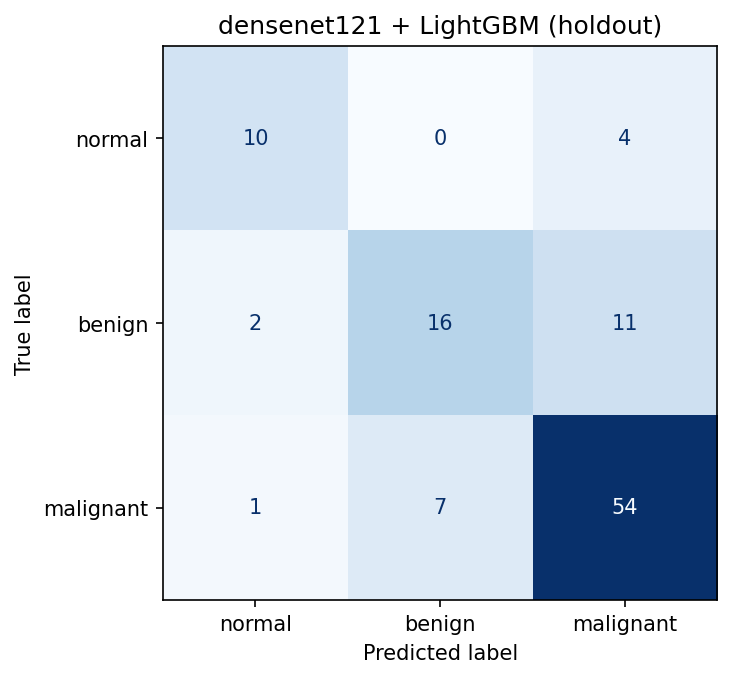

results/cm_three_holdout_densenet121_XGBoost.png


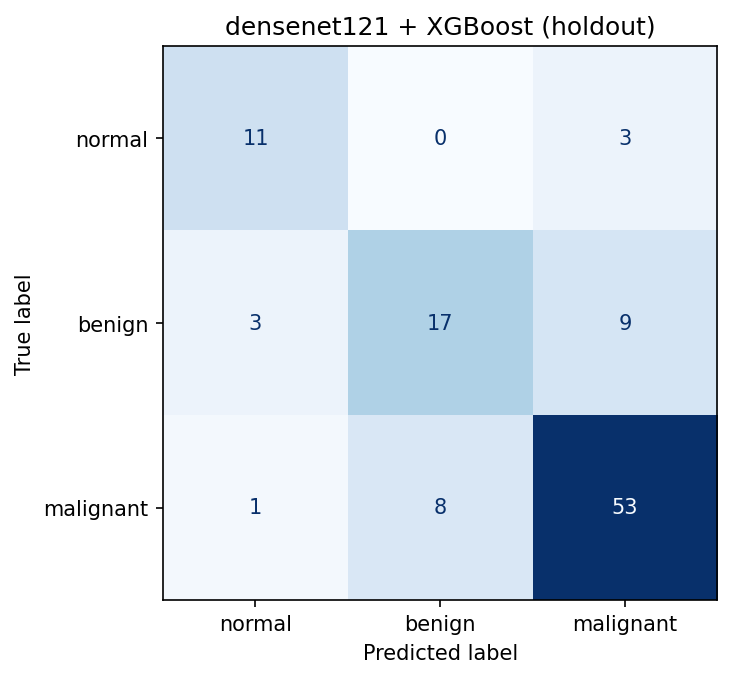

results/cm_three_holdout_resnet50_LightGBM.png


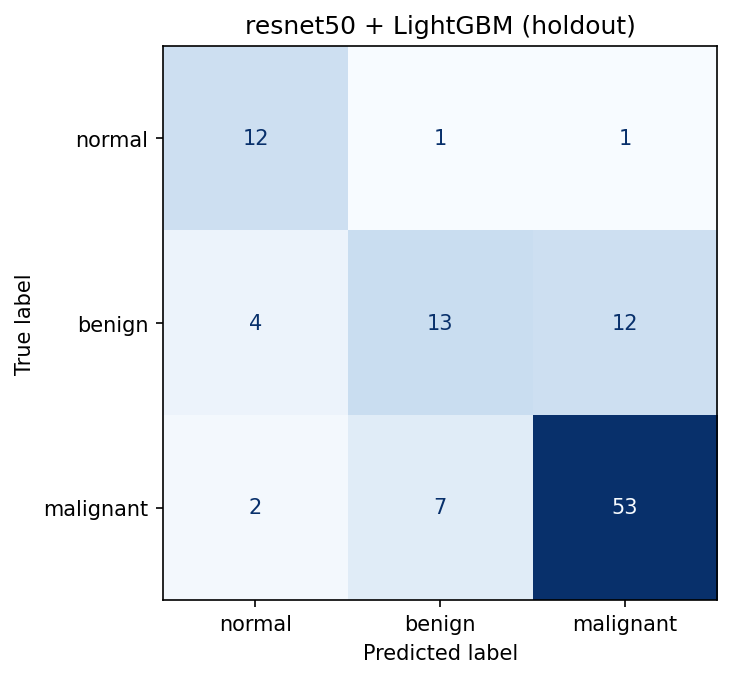

results/roc_three_holdout.png


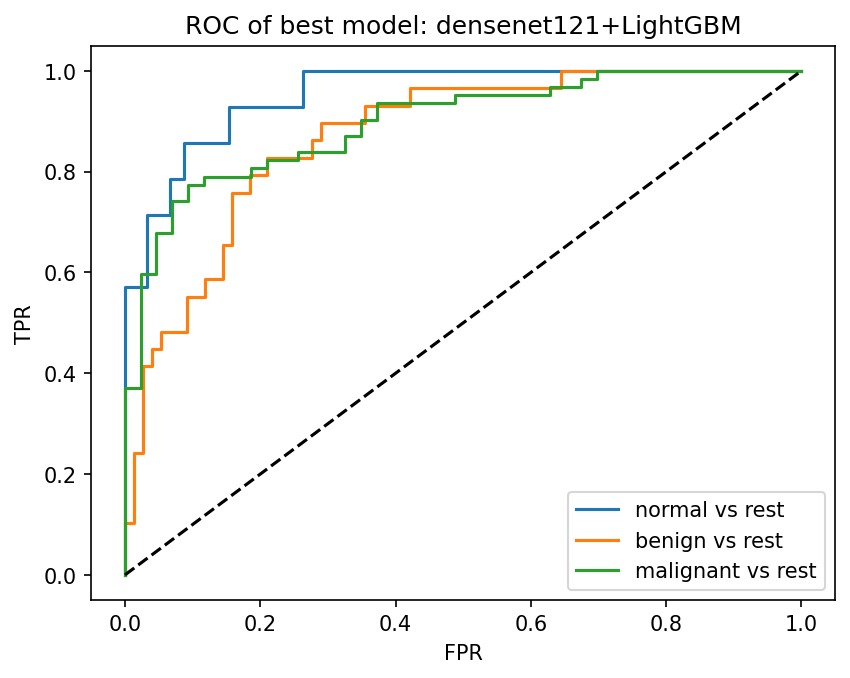

In [ ]:
import pandas as pd, glob
from IPython.display import Image, display

print(glob.glob('results/*'))                      # list of saved files
df = pd.read_csv('results/results_three_holdout.csv')
display(df.round(3))                               # full results table

for f in sorted(glob.glob('results/cm_three_holdout_*.png')) + glob.glob('results/roc_three_holdout.png'):
    print(f); display(Image(f))                    # confusion matrices and ROC curve

In [ ]:
import os, glob, re
for f in os.listdir('.'):
    new = re.sub(r'\s*\(1\)', '', f).replace(' .', '.')
    if new != f and os.path.isfile(f):
        os.replace(f, new)
print(sorted(x for x in os.listdir('.') if os.path.isfile(x)))

['Feature_Extractor_Comparison.xlsx', 'dataset_cleaned.zip', 'extract_features.py', 'fill_excel.py', 'train_boosting.py']


In [ ]:
import torch
print(torch.cuda.is_available())

True


In [ ]:
!unzip -q -o dataset_cleaned.zip
!pip install -q xgboost lightgbm
!ls dataset

[dataset_cleaned.zip]
  End-of-central-directory signature not found.  Either this file is not
  a zipfile, or it constitutes one disk of a multi-part archive.  In the
  latter case the central directory and zipfile comment will be found on
  the last disk(s) of this archive.
unzip:  cannot find zipfile directory in one of dataset_cleaned.zip or
        dataset_cleaned.zip.zip, and cannot find dataset_cleaned.zip.ZIP, period.
ls: cannot access 'dataset': No such file or directory


In [ ]:
!rm -f /content/dataset_cleaned.zip

In [ ]:
import os
print(os.path.exists('dataset_cleaned.zip'))

False


In [ ]:
!unzip -q -o dataset_cleaned.zip
!ls -la

total 53384
drwxr-xr-x 1 root root     4096 Nov  9 08:37 .
drwxr-xr-x 1 root root     4096 Nov  9 08:02 ..
drwxr-xr-x 4 root root     4096 Nov  6 16:54 .config
drwxr-xr-x 5 root root     4096 Nov  7 05:40 dataset
-rw-r--r-- 1 root root 54555459 Nov  9 08:31 dataset_cleaned.zip
-rw-r--r-- 1 root root     4670 Nov  9 08:08 extract_features.py
-rw-r--r-- 1 root root    23664 Nov  9 08:09 Feature_Extractor_Comparison.xlsx
-rw-r--r-- 1 root root    29703 Nov  9 08:32 files.zip
-rw-r--r-- 1 root root     1277 Nov  9 08:09 fill_excel.py
drwxr-xr-x 2 root root     4096 Nov  9 08:08 .ipynb_checkpoints
drwxr-xr-x 1 root root     4096 Nov  6 16:54 sample_data
-rw-r--r-- 1 root root    10970 Nov  9 08:10 train_boosting.py


In [ ]:
!pip install -q xgboost lightgbm
!ls dataset
!head -3 dataset/labels.csv

benign	labels.csv  malignant  normal  report.txt
path,cls,label3,group,orig_w,orig_h,crop_w,crop_h,fold,split
dataset/normal/normal_1.jpg,normal,0,normal_1,768,576,592,393,3,train
dataset/normal/normal_10.jpg,normal,0,normal_10,720,576,586,461,2,test


In [ ]:
!python extract_features.py --data dataset --out features --aug 4

vgg16 (3675, 512)
resnet50 (3675, 2048)
densenet121 (3675, 1024)
efficientnet_b0 (3675, 1280)
vit_b16 (3675, 768)


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!cp -r features /content/drive/MyDrive/liver_features

Mounted at /content/drive


In [ ]:
!grep -c "pair-with" train_boosting.py

2


In [ ]:
!python train_boosting.py --task three --eval holdout --quick --pca 0.95 --max-aug 2 --boosters XGBoost LightGBM --xgb-gpu --pair-with efficientnet_b0 --only-fused --out results_fused

task=three eval=holdout images=735 classes={'normal': 100, 'benign': 200, 'malignant': 435}
>>> efficientnet_b0+densenet121 + XGBoost ...
/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [09:00:33] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)
{'backbone': 'efficientnet_b0+densenet121', 'booster': 'XGBoost', 'cv_AUC': np.float64(0.856), 'val_AUC': np.float64(0.836), 'test_accuracy': 0.762, 'test_precision': 0.706, 'test_recall': 0.762, 'test_F1': 0.708, 'test_AUC': np.float64(0.877), 'best_params': '{"learning_rate": 0.1, "max_depth": 3, "n_esti

In [ ]:
!python fill_excel.py results_fused/results_three_holdout.csv

Filled 8 of 8 rows -> Feature_Extractor_Comparison_filled.xlsx


In [ ]:
!zip -r files.zip extract_features.py train_boosting.py fill_excel.py Feature_Extractor_Comparison.xlsx Feature_Extractor_Comparison_filled.xlsx results_fused
from google.colab import files
files.download('files.zip')

updating: extract_features.py (deflated 56%)
updating: train_boosting.py (deflated 62%)
updating: fill_excel.py (deflated 46%)
updating: Feature_Extractor_Comparison.xlsx (deflated 7%)
  adding: Feature_Extractor_Comparison_filled.xlsx (deflated 6%)
  adding: results_fused/ (stored 0%)
  adding: results_fused/cm_three_holdout_efficientnet_b0+resnet50_LightGBM.png (deflated 17%)
  adding: results_fused/results_three_holdout.csv (deflated 70%)
  adding: results_fused/roc_three_holdout.png (deflated 13%)
  adding: results_fused/cm_three_holdout_efficientnet_b0+vgg16_LightGBM.png (deflated 18%)
  adding: results_fused/cm_three_holdout_efficientnet_b0+vgg16_XGBoost.png (deflated 18%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os, glob, re, shutil, torch
import pandas as pd

# 0. fix browser-renamed files like "name (1).py"
for f in os.listdir('.'):
    new = re.sub(r'\s*\(1\)', '', f)
    if new != f and os.path.isfile(f): os.replace(f, new)

# 1. check uploads
need = ['extract_features.py', 'train_boosting.py', 'fill_excel_v2.py', 'Feature_Extractor_Comparison_v2.xlsx']
missing = [f for f in need if not os.path.exists(f)]
assert not missing, f"upload these first: {missing}"
parts = sorted(glob.glob('dataset_part_*'))
assert 'pair-with' in open('train_boosting.py').read(), "old train_boosting.py, upload the new one"

# 2. dataset: rebuild unless labels.csv is really there
if not os.path.exists('dataset/labels.csv'):
    shutil.rmtree('dataset', ignore_errors=True)
    if len(parts) == 6:
        !cat dataset_part_* > dataset_cleaned.zip
    assert os.path.exists('dataset_cleaned.zip') and os.path.getsize('dataset_cleaned.zip') == 54555459, "zip missing or wrong size: upload all 6 dataset_part_ files"
    !unzip -q -o dataset_cleaned.zip
assert os.path.exists('dataset/labels.csv'), "dataset/labels.csv still missing after unzip"
print("dataset ready:", sorted(os.listdir('dataset')))
!pip install -q xgboost lightgbm

# 3. GPU or CPU
gpu = torch.cuda.is_available()
xgb_flag = '--xgb-gpu' if gpu else ''
print("Running on GPU" if gpu else "Running on CPU (slower, about 1 hour)")

# 4. features (rebuilt unless 5 valid files exist)
if len(glob.glob('features/*.npz')) != 5:
    shutil.rmtree('features', ignore_errors=True)
    !python extract_features.py --data dataset --out features --aug 2
assert len(glob.glob('features/*.npz')) == 5, "feature extraction failed: scroll up to the first error"

# 5. combine ViT-B/16 with the other backbones
!python train_boosting.py --task three --eval holdout --quick --pca 0.95 --max-aug 2 --boosters XGBoost LightGBM {xgb_flag} --pair-with vit_b16 --only-fused --out results_fused_vit
assert os.path.exists('results_fused_vit/results_three_holdout.csv'), "training failed: scroll up to the first error"

# 6. results table
d = pd.read_csv('results_fused_vit/results_three_holdout.csv')
cols = ['backbone', 'booster', 'test_accuracy', 'test_precision', 'test_recall', 'test_F1', 'test_AUC']
print(d[cols].round(3).to_string(index=False))

# 7. fill Excel, zip, download
!python fill_excel_v2.py results_fused_vit/results_three_holdout.csv
!zip -qr files_v2.zip Feature_Extractor_Comparison_v2_filled.xlsx results_fused_vit
from google.colab import files
files.download('files_v2.zip')

AssertionError: zip missing or wrong size: upload all 6 dataset_part_ files

In [ ]:
!ls -l dataset_part_*

-rw-r--r-- 1 root root  9437184 Nov 10 04:41 dataset_part_00
-rw-r--r-- 1 root root  9437184 Nov 10 04:43 dataset_part_01
-rw-r--r-- 1 root root  9437184 Nov 10 04:51 dataset_part_02
-rw-r--r-- 1 root root  9437184 Nov 10 04:58 dataset_part_03
-rw-r--r-- 1 root root 13631488 Nov 10 05:09 dataset_part_04
-rw-r--r-- 1 root root  7369539 Nov 10 05:09 dataset_part_05


In [ ]:
!ls -l dataset_part_*

-rw-r--r-- 1 root root 9437184 Nov 10 04:41 dataset_part_00
-rw-r--r-- 1 root root 9437184 Nov 10 04:43 dataset_part_01
-rw-r--r-- 1 root root 9437184 Nov 10 04:51 dataset_part_02
-rw-r--r-- 1 root root 9437184 Nov 10 04:58 dataset_part_03
-rw-r--r-- 1 root root 9437184 Nov 10 05:41 dataset_part_04
-rw-r--r-- 1 root root 7369539 Nov 10 05:42 dataset_part_05


In [ ]:
import os, glob, re, shutil, subprocess, torch
import pandas as pd

def sh(cmd):
    p = subprocess.Popen(cmd, shell=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in p.stdout: print(line, end='')
    p.wait()
    assert p.returncode == 0, f"command failed: {cmd}"

# fix browser-renamed files like "name (1).py"
for f in os.listdir('.'):
    new = re.sub(r'\s*\(1\)', '', f)
    if new != f and os.path.isfile(f): os.replace(f, new)

# check uploads
need = ['extract_features.py', 'train_boosting.py', 'fill_excel_v2.py', 'Feature_Extractor_Comparison_v2.xlsx']
missing = [f for f in need if not os.path.exists(f)]
assert not missing, f"upload these first: {missing}"
assert 'pair-with' in open('train_boosting.py').read(), "old train_boosting.py, upload the new one"

# dataset: check every part, then rebuild
EXPECTED = {f'dataset_part_0{i}': 9437184 for i in range(5)}
EXPECTED['dataset_part_05'] = 7369539
if not os.path.exists('dataset/labels.csv'):
    bad = [f"{n}: {os.path.getsize(n) if os.path.exists(n) else 'MISSING'} (expected {s})" for n, s in EXPECTED.items()
           if not os.path.exists(n) or os.path.getsize(n) != s]
    assert not bad, "re-upload these dataset parts -> " + "; ".join(bad)
    shutil.rmtree('dataset', ignore_errors=True)
    sh('cat dataset_part_00 dataset_part_01 dataset_part_02 dataset_part_03 dataset_part_04 dataset_part_05 > dataset_cleaned.zip')
    sh('unzip -q -o dataset_cleaned.zip')
assert os.path.exists('dataset/labels.csv'), "dataset/labels.csv still missing after unzip"
print("dataset ready:", sorted(os.listdir('dataset')))
sh('pip install -q xgboost lightgbm')

# GPU or CPU
gpu = torch.cuda.is_available()
xgb_flag = '--xgb-gpu' if gpu else ''
print("Running on GPU" if gpu else "Running on CPU (slower, about 1 hour)")

# features
if len(glob.glob('features/*.npz')) != 5:
    shutil.rmtree('features', ignore_errors=True)
    sh('python extract_features.py --data dataset --out features --aug 2')
assert len(glob.glob('features/*.npz')) == 5, "feature extraction failed"

# combine ViT-B/16 with the other backbones
sh(f'python train_boosting.py --task three --eval holdout --quick --pca 0.95 --max-aug 2 --boosters XGBoost LightGBM {xgb_flag} --pair-with vit_b16 --only-fused --out results_fused_vit')
assert os.path.exists('results_fused_vit/results_three_holdout.csv'), "training failed"

# results table
d = pd.read_csv('results_fused_vit/results_three_holdout.csv')
cols = ['backbone', 'booster', 'test_accuracy', 'test_precision', 'test_recall', 'test_F1', 'test_AUC']
print(d[cols].round(3).to_string(index=False))

# fill Excel, zip, download
sh('python fill_excel_v2.py results_fused_vit/results_three_holdout.csv')
sh('zip -qr files_v2.zip Feature_Extractor_Comparison_v2_filled.xlsx results_fused_vit')
from google.colab import files
files.download('files_v2.zip')

dataset ready: ['benign', 'labels.csv', 'malignant', 'normal', 'report.txt']
Running on CPU (slower, about 1 hour)
task=three eval=holdout images=735 classes={'normal': 100, 'benign': 200, 'malignant': 435}
>>> vit_b16+densenet121 + XGBoost ...
{'backbone': 'vit_b16+densenet121', 'booster': 'XGBoost', 'cv_AUC': np.float64(0.848), 'val_AUC': np.float64(0.852), 'test_accuracy': 0.79, 'test_precision': 0.755, 'test_recall': 0.747, 'test_F1': 0.747, 'test_AUC': np.float64(0.88), 'best_params': '{"learning_rate": 0.1, "max_depth": 3, "n_estimators": 100}', '_rank': np.float64(0.88)}
>>> vit_b16+densenet121 + LightGBM ...
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.wa

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>